In [1]:
!pip install -q scikit-learn tensorflow optuna pandas matplotlib seaborn

# Modelo BiLSTM + Seq2Seq com Mecanismo de Atenção — Abordagem A

## Motivação e Evolução Arquitetural

O modelo LSTM unidirecional (Fase 2) apresentou duas limitações claras:

1. **Degradação do erro a partir de t+4h** na Abordagem A (horária): o RMSE ultrapassou o limite operacional de 1,0 m/s;
2. **R² negativo** na Abordagem B (decaminutal): incapacidade estrutural do modelo de acompanhar tendências de alta variabilidade.

Ambas as limitações decorrem de três fatores arquiteturais do LSTM unidirecional:
- Processa a sequência apenas da esquerda para a direita, perdendo contexto futuro da janela;
- Gera todos os horizontes com uma única camada `Dense(6)` estática, sem autoarregressividade;
- Não possui mecanismo de ponderação dinâmica dos passos mais relevantes do passado.

A evolução proposta combina três componentes:

| Componente | Papel |
|---|---|
| **BiLSTM (Encoder)** | Lê a janela de 24h nos dois sentidos, capturando contexto bidirecional |
| **LSTM (Decoder)** | Gera as previsões de forma autorregressiva, passo a passo |
| **Atenção (Bahdanau)** | Pondera dinamicamente quais timesteps do encoder são mais relevantes para cada passo do decoder |

---

## Cenários Avaliados (Abordagem A — Resolução Horária)

Para evitar redundância com o baseline e focar nos cenários com maior potencial de ganho, serão avaliados apenas:

### Cenário C3 — `ws100_lidar_clean → ws100_lidar` (1h a 6h)
Entrada: LiDAR filtrado por Wavelet (sym18, Nível 2). Alvo: velocidade bruta do LiDAR.
Objetivo: verificar se a arquitetura Seq2Seq supera a limitação de t+4h do LSTM unidirecional.

### Cenário C4 — `ws100_lidar_clean + ws100_era5 → ws100_lidar` (1h a 6h)
Entrada: LiDAR filtrado + ERA5. Alvo: velocidade bruta do LiDAR.
Objetivo: verificar se a macro-escala do ERA5 melhora a previsão de horizontes maiores na nova arquitetura.

---

## Parâmetros Fixos (Herdados do Baseline)

| Parâmetro | Valor |
|---|---|
| Lookback | 24 timesteps (24h) |
| Horizonte | 6 passos (t+1h a t+6h) |
| Divisão | 70% treino / 15% val / 15% teste |
| Normalização | StandardScaler separado para X e y |
| Otimizador | Adam |
| Loss | MSE |
| Callbacks | EarlyStopping (patience=7) + ReduceLROnPlateau (patience=3, factor=0.5) |
| Épocas máximas | 50 (treinamento final) |
| Trials Optuna | 20 |
| Limite operacional | 1,0 m/s (referência eólica) |

In [ ]:
# ============================================================
# BLOCO 1 — IMPORTS
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import optuna
import warnings

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Input, Bidirectional, LSTM, Dense, Dropout,
    Attention, Concatenate, RepeatVector, TimeDistributed, Lambda
)
from tensorflow.keras.models import Model
import tensorflow.keras.backend as K

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Reprodutibilidade
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponível: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
## Funções Utilitárias Compartilhadas

In [ ]:
# ============================================================
# BLOCO 2 — FUNÇÕES UTILITÁRIAS
# ============================================================
LOOKBACK = 24
HORIZON  = 6


def create_sequences_multistep(X_data, y_data, lookback=LOOKBACK, horizon=HORIZON):
    """
    Gera janelas deslizantes para previsão multi-step.
    X_out: (N, lookback, n_features)
    y_out: (N, horizon)
    """
    X_out, y_out = [], []
    for i in range(len(X_data) - lookback - horizon + 1):
        X_out.append(X_data[i : i + lookback, :])
        y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
    return np.array(X_out), np.array(y_out)


def evaluate_per_step(y_real, y_pred, horizon=HORIZON, label=""):
    """
    Calcula e imprime RMSE, MAE e R² por passo do horizonte.
    Retorna arrays de rmse e mae por passo.
    """
    rmse_steps, mae_steps, r2_steps = [], [], []
    sep = "=" * 58
    print(f"\n{sep}")
    print(f"  AVALIAÇÃO MULTI-STEP — {label}")
    print(sep)
    for step in range(horizon):
        yr = y_real[:, step]
        yp = y_pred[:, step]
        rmse_s = np.sqrt(mean_squared_error(yr, yp))
        mae_s  = mean_absolute_error(yr, yp)
        r2_s   = r2_score(yr, yp)
        rmse_steps.append(rmse_s)
        mae_steps.append(mae_s)
        r2_steps.append(r2_s)
        flag = " ⚠️  > 1.0 m/s" if rmse_s > 1.0 else ""
        print(f"  t+{step+1}h → RMSE: {rmse_s:.3f} | MAE: {mae_s:.3f} | R²: {r2_s:.3f}{flag}")
    rmse_g = np.sqrt(mean_squared_error(y_real, y_pred))
    mae_g  = mean_absolute_error(y_real, y_pred)
    r2_g   = r2_score(y_real.flatten(), y_pred.flatten())
    print("-" * 58)
    print(f"  GLOBAL → RMSE: {rmse_g:.3f} | MAE: {mae_g:.3f} | R²: {r2_g:.3f}")
    print(sep + "\n")
    return np.array(rmse_steps), np.array(mae_steps), np.array(r2_steps)


def plot_degradation(rmse_steps, mae_steps, title, baseline_rmse=None, baseline_mae=None):
    """
    Gráfico de degradação do erro por horizonte.
    Exibe o baseline LSTM unidirecional (C3) para comparação direta quando fornecido.
    """
    steps_labels = [f"t+{i+1}h" for i in range(len(rmse_steps))]
    plt.figure(figsize=(9, 5))
    plt.plot(steps_labels, rmse_steps, marker="o", color="crimson",
             linewidth=2, label="RMSE BiLSTM Seq2Seq (m/s)")
    plt.plot(steps_labels, mae_steps,  marker="s", color="royalblue",
             linewidth=2, label="MAE BiLSTM Seq2Seq (m/s)")
    if baseline_rmse is not None:
        plt.plot(steps_labels, baseline_rmse, marker="^", color="salmon",
                 linewidth=1.5, linestyle="--", label="RMSE LSTM Baseline (m/s)")
    if baseline_mae is not None:
        plt.plot(steps_labels, baseline_mae, marker="v", color="cornflowerblue",
                 linewidth=1.5, linestyle="--", label="MAE LSTM Baseline (m/s)")
    plt.axhline(y=1.0, color="black", linestyle="--", linewidth=1.2,
                label="Limite Operacional (1,0 m/s)")
    plt.title(title, fontsize=12, fontweight="bold")
    plt.xlabel("Horizonte de Previsão", fontsize=10)
    plt.ylabel("Erro (m/s)", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_series(y_real, y_pred, step=0, label=""):
    """
    Série temporal Real vs Previsto para um passo do horizonte.
    """
    yr = y_real[:, step]
    yp = y_pred[:, step]
    rmse = np.sqrt(mean_squared_error(yr, yp))
    mae  = mean_absolute_error(yr, yp)
    r2   = r2_score(yr, yp)

    plt.figure(figsize=(12, 4))
    plt.plot(yr, label="Real LiDAR (m/s)", color="black", linewidth=1.2, alpha=0.85)
    plt.plot(yp, label=f"Previsto BiLSTM Seq2Seq (m/s)", color="royalblue",
             linewidth=1.2, alpha=0.85)
    plt.title(f"Série Temporal — {label} | t+{step+1}h", fontsize=12, fontweight="bold")
    plt.xlabel("Passos Temporais no Conjunto de Teste (Horas)", fontsize=10)
    plt.ylabel("Velocidade do Vento (m/s)", fontsize=10)
    plt.legend(loc="upper right", frameon=True, facecolor="white")
    plt.grid(True, linestyle="--", alpha=0.5)
    metrics_text = f"RMSE: {rmse:.3f} m/s\nMAE: {mae:.3f} m/s\nR²: {r2:.3f}"
    plt.gca().text(0.02, 0.95, metrics_text, transform=plt.gca().transAxes,
                   fontsize=10, verticalalignment="top",
                   bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9))
    plt.tight_layout()
    plt.show()


def plot_scatter(y_real, y_pred, step=0, label=""):
    """
    Dispersão Real vs Previsto para um passo do horizonte.
    """
    yr = y_real[:, step]
    yp = y_pred[:, step]
    r2 = r2_score(yr, yp)
    vmin = min(yr.min(), yp.min()) - 0.5
    vmax = max(yr.max(), yp.max()) + 0.5

    plt.figure(figsize=(5, 5))
    plt.scatter(yr, yp, alpha=0.4, s=15, color="royalblue", edgecolors="none")
    plt.plot([vmin, vmax], [vmin, vmax], "k--", linewidth=1, label="1:1 ideal")
    plt.title(f"Dispersão — {label} | t+{step+1}h (R²={r2:.3f})",
              fontsize=11, fontweight="bold")
    plt.xlabel("Real LiDAR (m/s)", fontsize=10)
    plt.ylabel("Previsto BiLSTM Seq2Seq (m/s)", fontsize=10)
    plt.legend(fontsize=9)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


print("Funções utilitárias carregadas.")

Funções utilitárias carregadas.


---
## Arquitetura BiLSTM + Seq2Seq com Atenção (Bahdanau)

### Fluxo de dados

```
X_enc (N, 24, n_feat)  →  Encoder BiLSTM  →  encoder_outputs (N, 24, 2*units)
                                           →  state_h, state_c (concatenados)

Decoder:
  Para cada passo t = 1..6:
    context  = Attention(query=decoder_h, keys=encoder_outputs)
    input_t  = [context ; decoder_input_t]
    decoder_h, decoder_c = LSTM(input_t, state=(decoder_h, decoder_c))
    output_t = Dense(1)(decoder_h)
```

### Decisão de implementação
Usamos a API funcional do Keras com um **loop autorregressivo em Python** no decoder durante o treinamento (`teacher forcing` desligado). Isso mantém a arquitetura transparente e compatível com Optuna sem depender de camadas experimentais do TF.

In [ ]:
# ============================================================
# BLOCO 3 — ARQUITETURA BiLSTM + Seq2Seq + ATENÇÃO
# ============================================================
from tensorflow.keras.layers import Reshape

def build_bilstm_seq2seq(lookback, n_features, horizon,
                          enc_units, dec_units, dense_units,
                          dropout_rate, learning_rate):
    """
    Constrói o modelo BiLSTM Encoder + LSTM Decoder com Atenção Bahdanau.

    Parâmetros
    ----------
    lookback    : tamanho da janela de entrada (24)
    n_features  : número de variáveis de entrada (1 ou 2)
    horizon     : número de passos a prever (6)
    enc_units   : unidades do BiLSTM encoder (resultado final = 2*enc_units)
    dec_units   : unidades do LSTM decoder
    dense_units : unidades da camada densa intermediária na saída
    dropout_rate: taxa de dropout aplicada após encoder e decoder
    learning_rate: taxa de aprendizado do Adam
    """

    # ---- ENCODER ----
    encoder_inputs = Input(shape=(lookback, n_features), name="encoder_input")

    # BiLSTM: return_sequences=True para alimentar atenção;
    # return_state=True para inicializar decoder.
    bilstm_layer = Bidirectional(
        LSTM(enc_units, return_sequences=True, return_state=True,
             activation="tanh", recurrent_dropout=0.0),
        name="encoder_bilstm"
    )
    # Saídas: all_outputs, fwd_h, fwd_c, bwd_h, bwd_c
    enc_out, fwd_h, fwd_c, bwd_h, bwd_c = bilstm_layer(encoder_inputs)
    # enc_out shape: (batch, lookback, 2*enc_units)

    # Concatenar estados fwd + bwd para inicializar o decoder
    enc_state_h = Concatenate(name="enc_state_h")([fwd_h, bwd_h])  # (batch, 2*enc_units)
    enc_state_c = Concatenate(name="enc_state_c")([fwd_c, bwd_c])  # (batch, 2*enc_units)

    # Projetar para dec_units se necessário (enc_units*2 pode != dec_units)
    state_h = Dense(dec_units, activation="tanh", name="proj_h")(enc_state_h)
    state_c = Dense(dec_units, activation="tanh", name="proj_c")(enc_state_c)

    # Dropout no encoder output (para regularização da atenção)
    enc_out_drop = Dropout(dropout_rate, name="enc_dropout")(enc_out)

    # ---- ATENÇÃO (Bahdanau / Luong via tf.keras.layers.Attention) ----
    # Usaremos a camada Attention do Keras no decoder loop.
    attention_layer = Attention(use_scale=True, name="attention")

    # ---- DECODER ----
    decoder_lstm = LSTM(dec_units, return_state=True, activation="tanh",
                        name="decoder_lstm")
    decoder_dense_mid = Dense(dense_units, activation="relu", name="decoder_dense_mid")
    decoder_dense_out = Dense(1, name="decoder_dense_out")
    decoder_drop = Dropout(dropout_rate, name="dec_dropout")

    # Usar camada de Reshape para expandir dimensão do h de forma compatível
    reshape_query = Reshape((1, dec_units), name="reshape_query")

    # Loop autorregressivo: a cada passo, usa o context vector da atenção
    # como input do decoder LSTM (sem teacher forcing).
    outputs = []
    # Estado inicial do decoder = projeção dos estados do encoder
    h, c = state_h, state_c

    for t in range(horizon):
        # Query compatível: estado oculto atual do decoder → (batch, 1, dec_units)
        query = reshape_query(h)

        # Context: atenção sobre todos os outputs do encoder
        # keys e values = enc_out_drop → (batch, lookback, 2*enc_units)
        context = attention_layer([query, enc_out_drop])  # (batch, 1, 2*enc_units)

        # Concatenar context com um vetor neutro de entrada (zero input)
        dec_input = context  # (batch, 1, 2*enc_units)

        # Passo do decoder LSTM
        dec_output, h, c = decoder_lstm(dec_input, initial_state=[h, c])
        # dec_output: (batch, dec_units)

        dec_output = decoder_drop(dec_output)
        dec_output = decoder_dense_mid(dec_output)        # (batch, dense_units)
        step_pred  = decoder_dense_out(dec_output)        # (batch, 1)
        outputs.append(step_pred)

    # Empilhar saídas: (batch, horizon)
    decoder_outputs = Concatenate(axis=1, name="predictions")(outputs)

    # ---- MODELO COMPLETO ----
    model = Model(inputs=encoder_inputs, outputs=decoder_outputs,
                  name="BiLSTM_Seq2Seq_Atencao")

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss="mse", metrics=["mae"])

    return model

---
# CENÁRIO C3 — `ws100_lidar_clean → ws100_lidar` (1h a 6h)

**Hipótese:** A arquitetura BiLSTM + Seq2Seq + Atenção supera o limite de t+4h que o LSTM unidirecional não conseguiu ultrapassar, mantendo RMSE < 1,0 m/s em todos os horizontes.

In [ ]:
# ============================================================
# BLOCO 4 — CARREGAMENTO E PRÉ-PROCESSAMENTO (C3)
# ============================================================
df = pd.read_parquet("data/approach_a.parquet")

# --- C3: LiDAR filtrado → LiDAR bruto ---
features_c3 = ["ws100_lidar_clean"]
target_c3   = "ws100_lidar"

n = len(df)
train_df = df.iloc[: int(n * 0.70)]
val_df   = df.iloc[int(n * 0.70) : int(n * 0.85)]
test_df  = df.iloc[int(n * 0.85) :]

# Scalers separados para X e y (mesmo padrão do baseline)
scaler_x_c3 = StandardScaler()
scaler_y_c3 = StandardScaler()

X_train_raw_c3 = scaler_x_c3.fit_transform(train_df[features_c3])
y_train_raw_c3 = scaler_y_c3.fit_transform(train_df[[target_c3]])

X_val_raw_c3   = scaler_x_c3.transform(val_df[features_c3])
y_val_raw_c3   = scaler_y_c3.transform(val_df[[target_c3]])

X_test_raw_c3  = scaler_x_c3.transform(test_df[features_c3])
y_test_raw_c3  = scaler_y_c3.transform(test_df[[target_c3]])

# Janelas multi-step
X_train_c3, y_train_c3 = create_sequences_multistep(X_train_raw_c3, y_train_raw_c3)
X_val_c3,   y_val_c3   = create_sequences_multistep(X_val_raw_c3,   y_val_raw_c3)
X_test_c3,  y_test_c3  = create_sequences_multistep(X_test_raw_c3,  y_test_raw_c3)

print(f"X_train shape: {X_train_c3.shape}  → (Amostras, Lookback, Features)")
print(f"y_train shape: {y_train_c3.shape}  → (Amostras, Horizonte)")
print(f"X_val   shape: {X_val_c3.shape}")
print(f"X_test  shape: {X_test_c3.shape}")

X_train shape: (857, 24, 1)  → (Amostras, Lookback, Features)
y_train shape: (857, 6)  → (Amostras, Horizonte)
X_val   shape: (161, 24, 1)
X_test  shape: (161, 24, 1)


In [ ]:
# ============================================================
# BLOCO 5 — OPTUNA: BUSCA DE HIPERPARÂMETROS (C3)
# ============================================================

def objective_c3(trial):
    enc_units    = trial.suggest_categorical("enc_units",    [32, 64, 128])
    dec_units    = trial.suggest_categorical("dec_units",    [32, 64, 128])
    dense_units  = trial.suggest_categorical("dense_units",  [16, 32, 64])
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.4, step=0.1)
    learning_rate= trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    batch_size   = trial.suggest_categorical("batch_size", [16, 32, 64])

    model = build_bilstm_seq2seq(
        lookback=LOOKBACK, n_features=X_train_c3.shape[2],
        horizon=HORIZON,
        enc_units=enc_units, dec_units=dec_units,
        dense_units=dense_units, dropout_rate=dropout_rate,
        learning_rate=learning_rate
    )

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    rl = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

    history = model.fit(
        X_train_c3, y_train_c3,
        validation_data=(X_val_c3, y_val_c3),
        epochs=20,
        batch_size=batch_size,
        callbacks=[es, rl],
        verbose=0
    )
    return min(history.history["val_loss"])


study_c3 = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)
study_c3.optimize(objective_c3, n_trials=20)

best_c3 = study_c3.best_params
print("\nMelhores Hiperparâmetros — C3:")
for k, v in best_c3.items():
    print(f"  {k}: {v}")


Melhores Hiperparâmetros — C3:
  enc_units: 64
  dec_units: 32
  dense_units: 32
  dropout_rate: 0.30000000000000004
  learning_rate: 0.0036601763145525648
  batch_size: 32


In [ ]:
# ============================================================
# BLOCO 6 — TREINAMENTO FINAL E AVALIAÇÃO (C3)
# ============================================================

model_c3 = build_bilstm_seq2seq(
    lookback=LOOKBACK, n_features=X_train_c3.shape[2],
    horizon=HORIZON,
    enc_units=best_c3["enc_units"],
    dec_units=best_c3["dec_units"],
    dense_units=best_c3["dense_units"],
    dropout_rate=best_c3["dropout_rate"],
    learning_rate=best_c3["learning_rate"]
)

es = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
rl = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

history_c3 = model_c3.fit(
    X_train_c3, y_train_c3,
    validation_data=(X_val_c3, y_val_c3),
    epochs=50,
    batch_size=best_c3["batch_size"],
    callbacks=[es, rl],
    verbose=1
)

# --- Inferência e desescalonamento ---
y_pred_scaled_c3 = model_c3.predict(X_test_c3)  # (N_test, 6)

# Desescalonamento seguro via reshape matricial
y_real_c3 = scaler_y_c3.inverse_transform(
    y_test_c3.reshape(-1, 1)
).reshape(-1, HORIZON)

y_pred_c3 = scaler_y_c3.inverse_transform(
    y_pred_scaled_c3.reshape(-1, 1)
).reshape(-1, HORIZON)

# --- Métricas por passo ---
# Valores do baseline LSTM (C3) para comparação — atualize com seus resultados reais
BASELINE_C3_RMSE = None  # ex: np.array([0.530, 0.700, 0.850, 1.050, 1.180, 1.293])
BASELINE_C3_MAE  = None  # ex: np.array([0.408, 0.530, 0.650, 0.820, 0.950, 1.050])

rmse_c3, mae_c3, r2_c3 = evaluate_per_step(
    y_real_c3, y_pred_c3, label="C3: LiDAR_clean → LiDAR (BiLSTM Seq2Seq)"
)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - loss: 0.6995 - mae: 0.6415 - val_loss: 0.6334 - val_mae: 0.6144 - learning_rate: 0.0037
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.6004 - mae: 0.5899 - val_loss: 0.5405 - val_mae: 0.5674 - learning_rate: 0.0037
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.4897 - mae: 0.5296 - val_loss: 0.4419 - val_mae: 0.5057 - learning_rate: 0.0037
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.4272 - mae: 0.4902 - val_loss: 0.3949 - val_mae: 0.4766 - learning_rate: 0.0037
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.3803 - mae: 0.4604 - val_loss: 0.3538 - val_mae: 0.4518 - learning_rate: 0.0037
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.3590 - mae: 0.4476 - val_loss: 0.3759 - val_mae: 0.4726 - learning_rate: 0.0037
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.3409 - mae: 0.4345 - val_loss: 0.3474 - val_mae: 0.4589 - learning_rate: 0.0037
Epoch 8/50
27

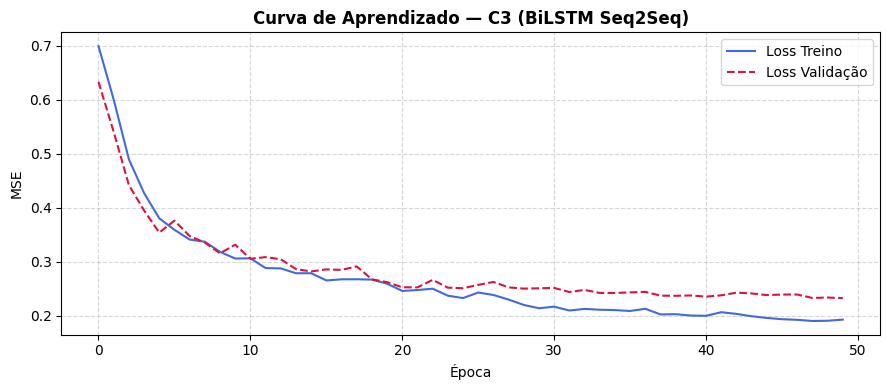

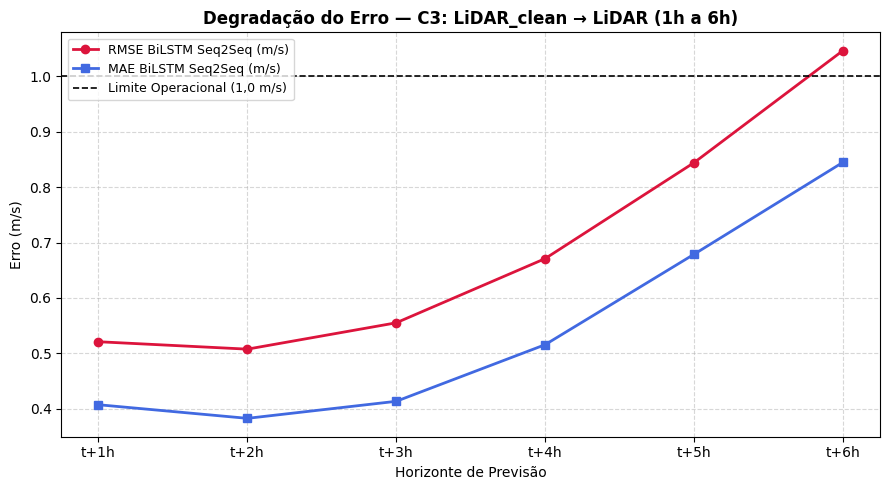

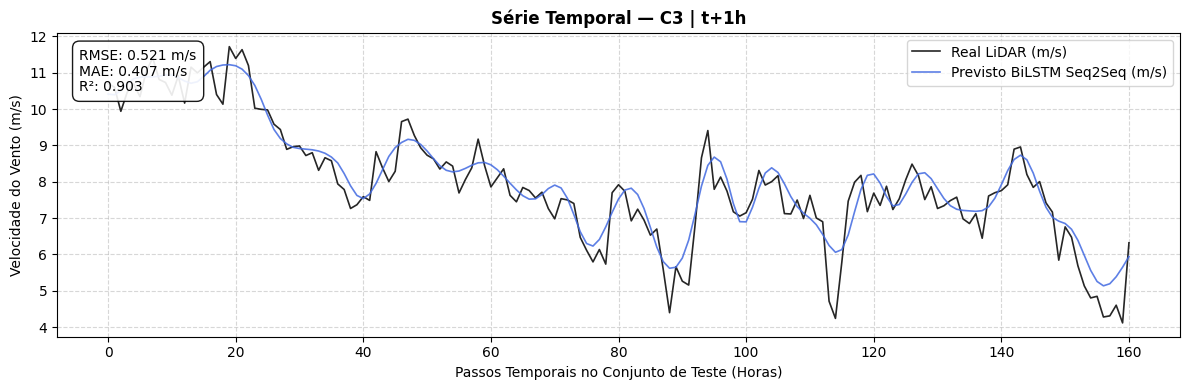

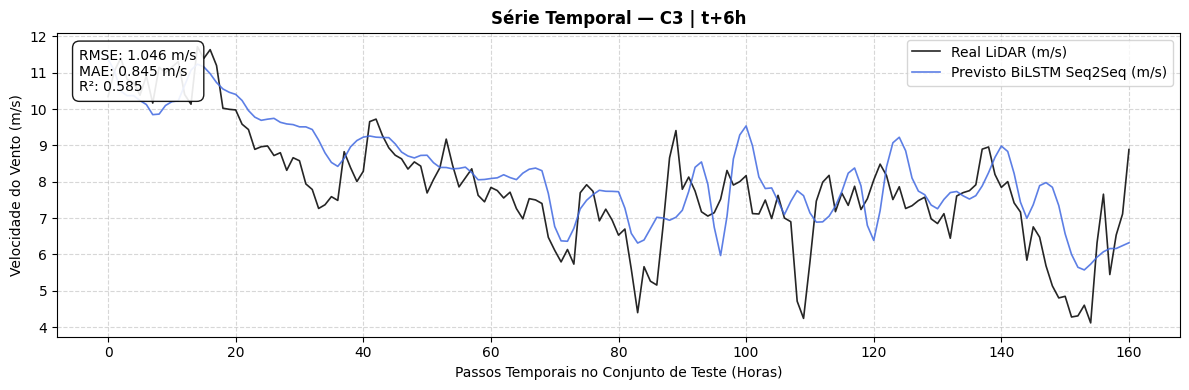

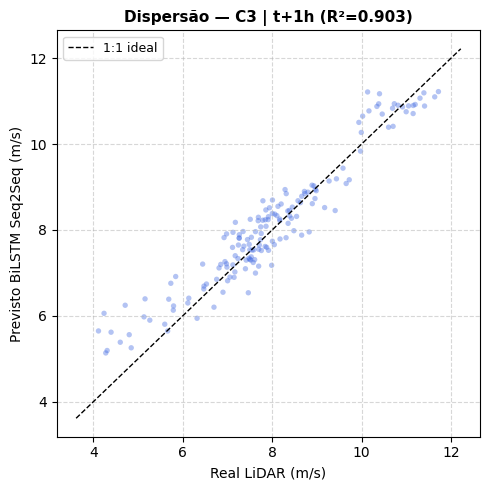

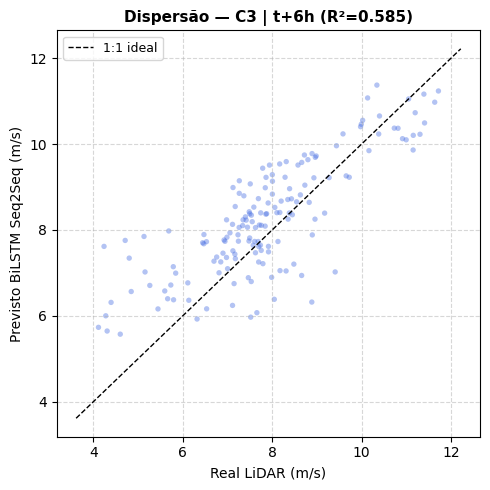

In [ ]:
# ============================================================
# BLOCO 7 — VISUALIZAÇÕES (C3)
# ============================================================

# 7.1 — Curva de aprendizado
plt.figure(figsize=(9, 4))
plt.plot(history_c3.history["loss"],     label="Loss Treino",    color="royalblue")
plt.plot(history_c3.history["val_loss"], label="Loss Validação", color="crimson", linestyle="--")
plt.title("Curva de Aprendizado — C3 (BiLSTM Seq2Seq)", fontsize=12, fontweight="bold")
plt.xlabel("Época"); plt.ylabel("MSE")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

# 7.2 — Degradação do erro por horizonte (com comparação ao baseline)
plot_degradation(
    rmse_c3, mae_c3,
    title="Degradação do Erro — C3: LiDAR_clean → LiDAR (1h a 6h)",
    baseline_rmse=BASELINE_C3_RMSE,
    baseline_mae=BASELINE_C3_MAE
)

# 7.3 — Série temporal para t+1h e t+6h
for step in [0, 5]:
    plot_series(y_real_c3, y_pred_c3, step=step, label="C3")

# 7.4 — Dispersão para t+1h e t+6h
for step in [0, 5]:
    plot_scatter(y_real_c3, y_pred_c3, step=step, label="C3")

---
# CENÁRIO C4 — `ws100_lidar_clean + ws100_era5 → ws100_lidar` (1h a 6h)

**Hipótese:** A adição do ERA5 como variável exógena de macroescala, combinada com a nova arquitetura, melhora especificamente os horizontes mais longos (t+4h a t+6h) onde a âncora local do LiDAR perde correlação com o futuro.

In [ ]:
# ============================================================
# BLOCO 8 — CARREGAMENTO E PRÉ-PROCESSAMENTO (C4)
# ============================================================

# --- C4: LiDAR filtrado + ERA5 → LiDAR bruto ---
features_c4 = ["ws100_lidar_clean", "ws100_era5"]
target_c4   = "ws100_lidar"

# Reuso das mesmas fatias temporais
scaler_x_c4 = StandardScaler()
scaler_y_c4 = StandardScaler()

X_train_raw_c4 = scaler_x_c4.fit_transform(train_df[features_c4])
y_train_raw_c4 = scaler_y_c4.fit_transform(train_df[[target_c4]])

X_val_raw_c4   = scaler_x_c4.transform(val_df[features_c4])
y_val_raw_c4   = scaler_y_c4.transform(val_df[[target_c4]])

X_test_raw_c4  = scaler_x_c4.transform(test_df[features_c4])
y_test_raw_c4  = scaler_y_c4.transform(test_df[[target_c4]])

X_train_c4, y_train_c4 = create_sequences_multistep(X_train_raw_c4, y_train_raw_c4)
X_val_c4,   y_val_c4   = create_sequences_multistep(X_val_raw_c4,   y_val_raw_c4)
X_test_c4,  y_test_c4  = create_sequences_multistep(X_test_raw_c4,  y_test_raw_c4)

print(f"X_train shape: {X_train_c4.shape}  → (Amostras, Lookback, Features)")
print(f"y_train shape: {y_train_c4.shape}  → (Amostras, Horizonte)")

X_train shape: (857, 24, 2)  → (Amostras, Lookback, Features)
y_train shape: (857, 6)  → (Amostras, Horizonte)


In [ ]:
# ============================================================
# BLOCO 9 — OPTUNA: BUSCA DE HIPERPARÂMETROS (C4)
# ============================================================

def objective_c4(trial):
    enc_units    = trial.suggest_categorical("enc_units",    [32, 64, 128])
    dec_units    = trial.suggest_categorical("dec_units",    [32, 64, 128])
    dense_units  = trial.suggest_categorical("dense_units",  [16, 32, 64])
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.4, step=0.1)
    learning_rate= trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    batch_size   = trial.suggest_categorical("batch_size", [16, 32, 64])

    model = build_bilstm_seq2seq(
        lookback=LOOKBACK, n_features=X_train_c4.shape[2],
        horizon=HORIZON,
        enc_units=enc_units, dec_units=dec_units,
        dense_units=dense_units, dropout_rate=dropout_rate,
        learning_rate=learning_rate
    )

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    rl = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

    history = model.fit(
        X_train_c4, y_train_c4,
        validation_data=(X_val_c4, y_val_c4),
        epochs=20,
        batch_size=batch_size,
        callbacks=[es, rl],
        verbose=0
    )
    return min(history.history["val_loss"])


study_c4 = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)
study_c4.optimize(objective_c4, n_trials=20)

best_c4 = study_c4.best_params
print("\nMelhores Hiperparâmetros — C4:")
for k, v in best_c4.items():
    print(f"  {k}: {v}")


Melhores Hiperparâmetros — C4:
  enc_units: 128
  dec_units: 64
  dense_units: 32
  dropout_rate: 0.4
  learning_rate: 0.004364540371105975
  batch_size: 32


In [ ]:
# ============================================================
# BLOCO 10 — TREINAMENTO FINAL E AVALIAÇÃO (C4)
# ============================================================

model_c4 = build_bilstm_seq2seq(
    lookback=LOOKBACK, n_features=X_train_c4.shape[2],
    horizon=HORIZON,
    enc_units=best_c4["enc_units"],
    dec_units=best_c4["dec_units"],
    dense_units=best_c4["dense_units"],
    dropout_rate=best_c4["dropout_rate"],
    learning_rate=best_c4["learning_rate"]
)

es = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
rl = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

history_c4 = model_c4.fit(
    X_train_c4, y_train_c4,
    validation_data=(X_val_c4, y_val_c4),
    epochs=50,
    batch_size=best_c4["batch_size"],
    callbacks=[es, rl],
    verbose=1
)

y_pred_scaled_c4 = model_c4.predict(X_test_c4)

y_real_c4 = scaler_y_c4.inverse_transform(
    y_test_c4.reshape(-1, 1)
).reshape(-1, HORIZON)

y_pred_c4 = scaler_y_c4.inverse_transform(
    y_pred_scaled_c4.reshape(-1, 1)
).reshape(-1, HORIZON)

# Valores do baseline LSTM (C4) para comparação — atualize com seus resultados reais
BASELINE_C4_RMSE = None  # ex: np.array([0.534, 0.720, 0.900, 1.100, 1.250, 1.381])
BASELINE_C4_MAE  = None

rmse_c4, mae_c4, r2_c4 = evaluate_per_step(
    y_real_c4, y_pred_c4, label="C4: LiDAR_clean + ERA5 → LiDAR (BiLSTM Seq2Seq)"
)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 56ms/step - loss: 0.6496 - mae: 0.6135 - val_loss: 0.5556 - val_mae: 0.5626 - learning_rate: 0.0044
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.4952 - mae: 0.5299 - val_loss: 0.5057 - val_mae: 0.5445 - learning_rate: 0.0044
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.4107 - mae: 0.4763 - val_loss: 0.4556 - val_mae: 0.5227 - learning_rate: 0.0044
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.3943 - mae: 0.4691 - val_loss: 0.4629 - val_mae: 0.5364 - learning_rate: 0.0044
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.3581 - mae: 0.4438 - val_loss: 0.4192 - val_mae: 0.5072 - learning_rate: 0.0044
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.3233 - mae: 0.4256 - val_loss: 0.4522 - val_mae: 0.5288 - learning_rate: 0.0044
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.3151 - mae: 0.4192 - val_loss: 0.4449 - val_mae: 0.5329 - learning_rate: 0.0044
Epoch 8/50
2

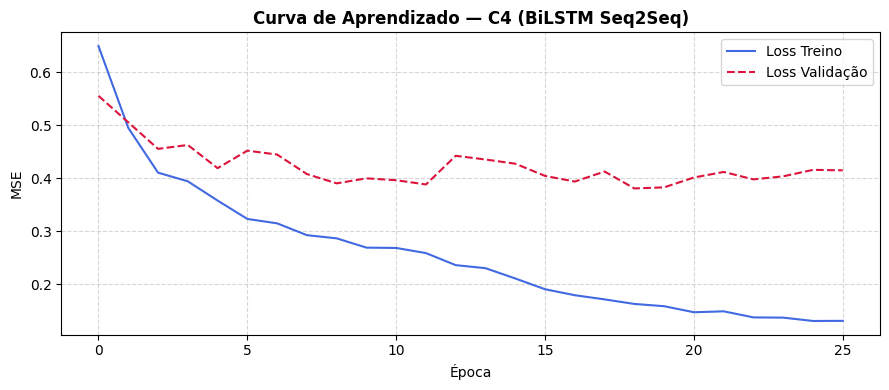

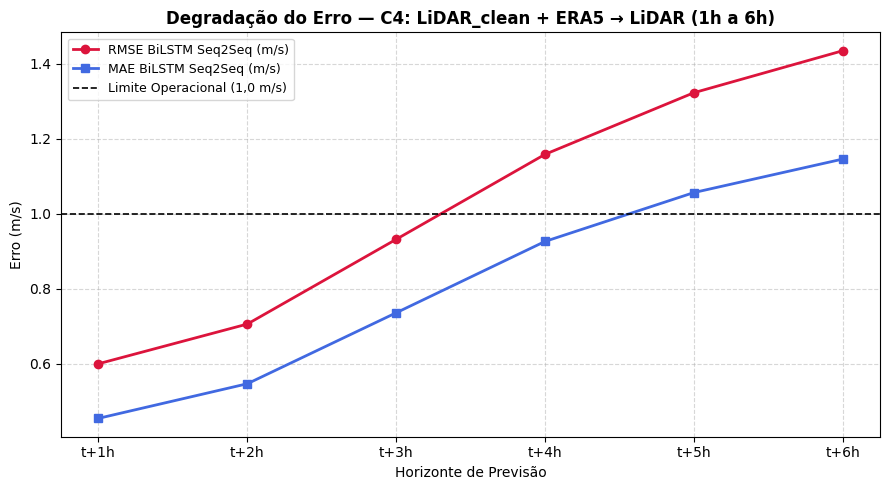

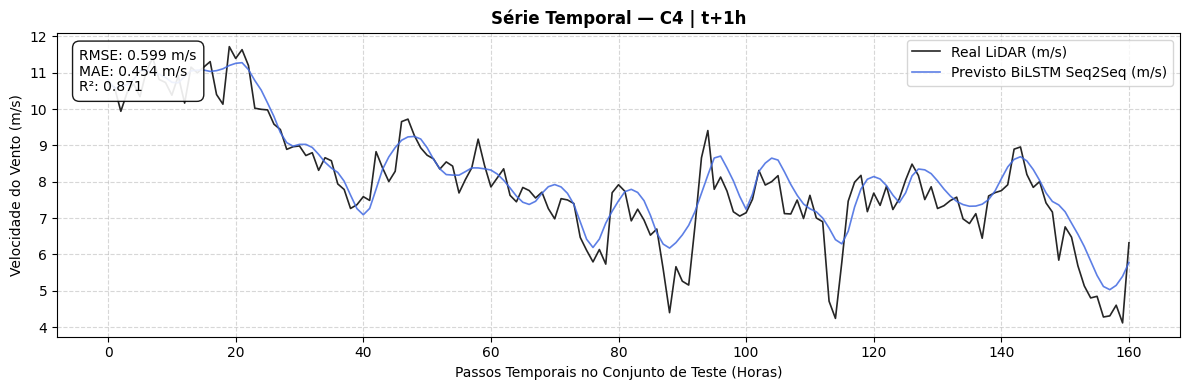

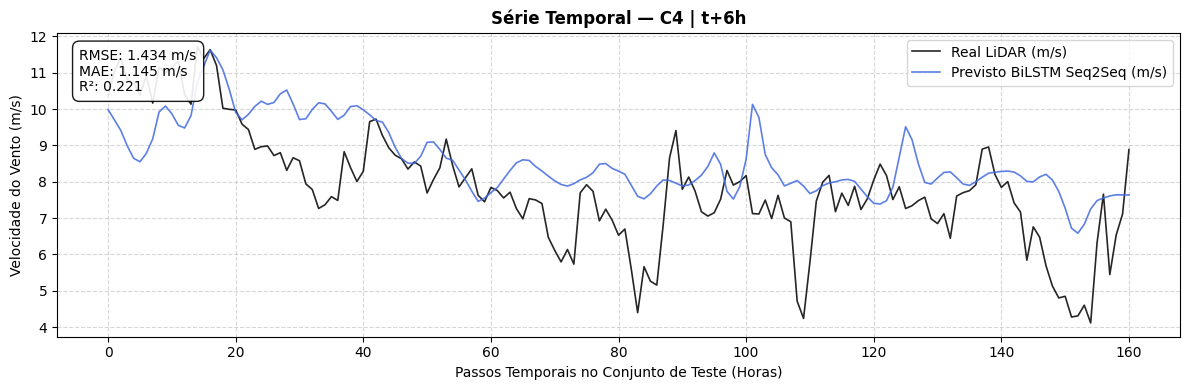

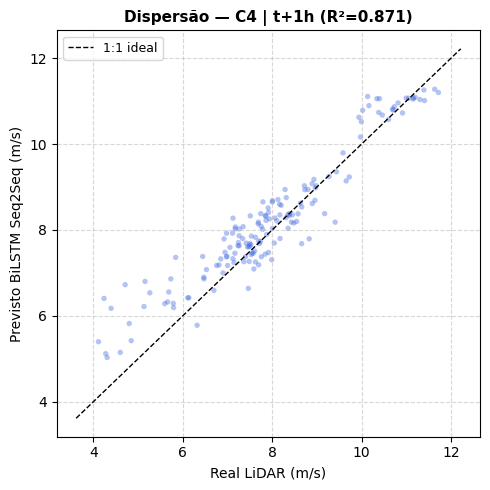

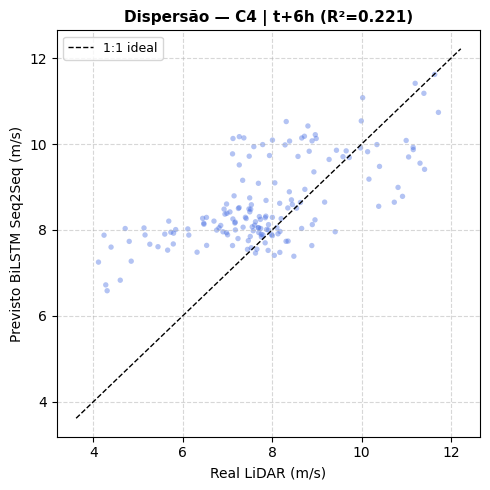

In [ ]:
# ============================================================
# BLOCO 11 — VISUALIZAÇÕES (C4)
# ============================================================

# 11.1 — Curva de aprendizado
plt.figure(figsize=(9, 4))
plt.plot(history_c4.history["loss"],     label="Loss Treino",    color="royalblue")
plt.plot(history_c4.history["val_loss"], label="Loss Validação", color="crimson", linestyle="--")
plt.title("Curva de Aprendizado — C4 (BiLSTM Seq2Seq)", fontsize=12, fontweight="bold")
plt.xlabel("Época"); plt.ylabel("MSE")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()

# 11.2 — Degradação do erro
plot_degradation(
    rmse_c4, mae_c4,
    title="Degradação do Erro — C4: LiDAR_clean + ERA5 → LiDAR (1h a 6h)",
    baseline_rmse=BASELINE_C4_RMSE,
    baseline_mae=BASELINE_C4_MAE
)

# 11.3 — Série temporal para t+1h e t+6h
for step in [0, 5]:
    plot_series(y_real_c4, y_pred_c4, step=step, label="C4")

# 11.4 — Dispersão para t+1h e t+6h
for step in [0, 5]:
    plot_scatter(y_real_c4, y_pred_c4, step=step, label="C4")

---
## Comparação Final: C3 vs C4 (BiLSTM Seq2Seq)

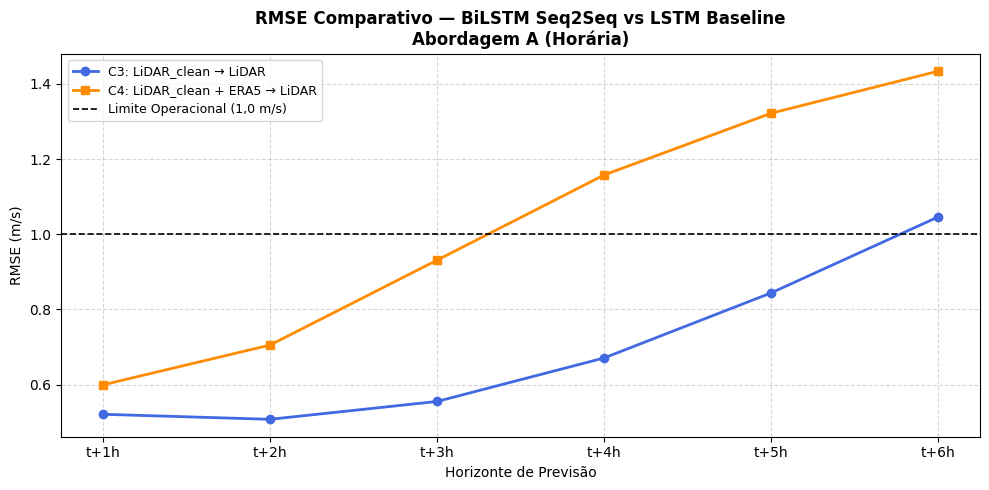


  TABELA COMPARATIVA — RMSE por Horizonte (m/s)
  Horizonte       C3 BiLSTM    C4 BiLSTM
----------------------------------------------------------------------
  t+1h               0.521        0.599
  t+2h               0.508        0.705
  t+3h               0.555        0.931
  t+4h               0.671        1.158
  t+5h               0.844        1.322
  t+6h               1.046        1.434

  TABELA COMPARATIVA — R² por Horizonte
  Horizonte       C3 BiLSTM    C4 BiLSTM
--------------------------------------------------
  t+1h               0.903        0.871
  t+2h               0.906        0.819
  t+3h               0.887        0.683
  t+4h               0.835        0.507
  t+5h               0.735        0.349
  t+6h               0.585        0.221


In [ ]:
# ============================================================
# BLOCO 12 — COMPARAÇÃO CONSOLIDADA C3 vs C4
# ============================================================

steps_labels = [f"t+{i+1}h" for i in range(HORIZON)]

# --- Gráfico comparativo RMSE ---
plt.figure(figsize=(10, 5))
plt.plot(steps_labels, rmse_c3, marker="o", color="royalblue",
         linewidth=2, label="C3: LiDAR_clean → LiDAR")
plt.plot(steps_labels, rmse_c4, marker="s", color="darkorange",
         linewidth=2, label="C4: LiDAR_clean + ERA5 → LiDAR")
if BASELINE_C3_RMSE is not None:
    plt.plot(steps_labels, BASELINE_C3_RMSE, marker="^", color="cornflowerblue",
             linewidth=1.5, linestyle="--", label="Baseline C3 (LSTM Unid.)")
if BASELINE_C4_RMSE is not None:
    plt.plot(steps_labels, BASELINE_C4_RMSE, marker="v", color="sandybrown",
             linewidth=1.5, linestyle="--", label="Baseline C4 (LSTM Unid.)")
plt.axhline(y=1.0, color="black", linestyle="--", linewidth=1.2,
            label="Limite Operacional (1,0 m/s)")
plt.title("RMSE Comparativo — BiLSTM Seq2Seq vs LSTM Baseline\nAbordagem A (Horária)",
          fontsize=12, fontweight="bold")
plt.xlabel("Horizonte de Previsão", fontsize=10)
plt.ylabel("RMSE (m/s)", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# --- Tabela consolidada ---
print("\n" + "=" * 70)
print("  TABELA COMPARATIVA — RMSE por Horizonte (m/s)")
print("=" * 70)
print(f"  {'Horizonte':<12} {'C3 BiLSTM':>12} {'C4 BiLSTM':>12}", end="")
if BASELINE_C3_RMSE is not None:
    print(f" {'C3 Baseline':>12} {'C4 Baseline':>12}", end="")
print()
print("-" * 70)
for i in range(HORIZON):
    line = f"  t+{i+1}h        {rmse_c3[i]:>12.3f} {rmse_c4[i]:>12.3f}"
    if BASELINE_C3_RMSE is not None:
        line += f" {BASELINE_C3_RMSE[i]:>12.3f}"
    if BASELINE_C4_RMSE is not None:
        line += f" {BASELINE_C4_RMSE[i]:>12.3f}"
    print(line)
print("=" * 70)

# --- Tabela R² consolidada ---
print("\n" + "=" * 50)
print("  TABELA COMPARATIVA — R² por Horizonte")
print("=" * 50)
print(f"  {'Horizonte':<12} {'C3 BiLSTM':>12} {'C4 BiLSTM':>12}")
print("-" * 50)
for i in range(HORIZON):
    print(f"  t+{i+1}h        {r2_c3[i]:>12.3f} {r2_c4[i]:>12.3f}")
print("=" * 50)

---
## Conclusões

*(Preencher após execução com os resultados reais)*

### Questões a responder com os resultados

**1. A arquitetura BiLSTM + Seq2Seq + Atenção superou o limite de t+4h?**
- Verificar se RMSE permanece < 1,0 m/s nos passos t+4h, t+5h e t+6h para C3.
- Comparar com o baseline LSTM unidirecional (C3) que rompeu o limite no SECOMP.

**2. O ERA5 agrega valor na nova arquitetura (C4 vs C3)?**
- No baseline, C4 não melhorou a 1h e piorou a 6h (conflito de gradientes).
- Com o mecanismo de atenção, o decoder pode ponderar o ERA5 apenas nos passos onde ele é informativo — verificar se isso se confirma.

**3. O R² permanece positivo em todos os horizontes?**
- R² negativo foi o sinal de alarme da Abordagem B no baseline.
- O Seq2Seq autorregressivo deve resolver a incapacidade de acompanhar tendências.

**4. Há ganho marginal decrescente na capacidade da arquitetura?**
- Se RMSE ainda cresce substancialmente após t+4h, o próximo passo é aumentar o volume de dados (Abordagem B, 10 min, ~4.184 amostras).
- Se o ganho for satisfatório, a mesma arquitetura pode ser aplicada à Abordagem B como validação cruzada.